# Análise exploratória — Parte 1 (Carpet)

O rótulo é uma faixa de frequência, então a pergunta é "esta banda é carpet?", não "este sinal tem carpet?". Carpet é ruído
de banda larga perto de ressonâncias: energia acima do piso, sem periodicidade e sem impulsividade.

Roteiro: 2. Dados e labels · 3. Tempo · 4. Frequência · 5. Tempo-frequência · 6. Envelope · 7. Ranking de features por banda ·
8. Modelos de ML · 9. Conclusões · 10. Features não calculadas

## 2. Imports e steup inicial

In [59]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps, stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_loader import load_part1  # noqa: E402

# Mesma paleta do eda_part2 (validada para daltonismo): carpet = laranja, fora do carpet = azul
C = {"carpet": "#eb6834", "outside": "#2a78d6", "neutral": "#8a8a85"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 1.6,
})
pd.set_option("display.width", 160, "display.max_columns", 30)
rng = np.random.default_rng(0)

waves, label_regions = load_part1()
signals = {}                                   # sample_id -> (sinal sem média, fs)
for sid, w in waves.items():
    t = np.asarray(w.time)
    x = np.asarray(w.signal, dtype=float)
    signals[sid] = (x - x.mean(), 1.0 / np.median(np.diff(t)))
regions = {sid: [(r.start_hz, r.end_hz) for r in rr] for sid, rr in label_regions.items()}
del waves, label_regions

inv = pd.DataFrame({
    sid: {"fs": fs, "n": len(x), "df": fs / len(x), "n_regions": len(regions[sid])}
    for sid, (x, fs) in signals.items()
}).T
inv["has_carpet"] = inv["n_regions"] > 0
print(f"{len(inv)} sinais | {int(inv.has_carpet.sum())} com carpet | {int((~inv.has_carpet).sum())} sem")
inv.describe().round(2)

126 sinais | 100 com carpet | 26 sem


,fs,n,df,n_regions
count,126.00,126.00,126.00,126.00
mean,15774.33,30850.03,0.59,1.19
std,2246.33,6608.39,0.47,0.86
min,7845.00,4096.00,0.48,0.00
25%,15816.25,32768.00,0.48,1.00
50%,16110.00,32768.00,0.49,1.00
75%,16181.00,32768.00,0.49,2.00
max,31674.00,32768.00,3.92,4.00


### 2.1 Qualidade dos sinais

Checagem de valores inválidos (NaN/inf) e de saturação. `clip_frac` é a fração de amostras com |x| ≥ 99,9% do
máximo do sinal: num sinal saturado, muitas amostras ficam "grudadas" no teto; num sinal normal, só o pico chega lá.

Também listamos as combinações de taxa de amostragem e comprimento, porque a Parte 1 não é homogênea.

In [60]:
def clip_fraction(x):
    peak = np.max(np.abs(x))
    return float(np.mean(np.abs(x) >= 0.999 * peak))


inv["finite"] = [bool(np.isfinite(signals[sid][0]).all()) for sid in inv.index]
inv["clip_frac"] = [clip_fraction(signals[sid][0]) for sid in inv.index]
inv["n_unique_values"] = [np.unique(signals[sid][0]).size for sid in inv.index]

print("Sinais com NaN/inf:", int((~inv.finite).sum()))
print("Sinais com possível clipping (> 0,1% das amostras no pico):", int((inv.clip_frac > 1e-3).sum()))
print("Menor nº de valores distintos num sinal:", int(inv.n_unique_values.min()), "de", int(inv.loc[inv.n_unique_values.idxmin(), "n"]))
print("\nCombinações de fs e comprimento (nº de sinais):")
print(inv.assign(fs_khz=(inv.fs / 1000).round(1), n=inv.n.astype(int))
         .groupby(["fs_khz", "n"]).size().rename("sinais").to_string())

Sinais com NaN/inf: 0
Sinais com possível clipping (> 0,1% das amostras no pico): 0
Menor nº de valores distintos num sinal: 4096 de 4096

Combinações de fs e comprimento (nº de sinais):
fs_khz  n    
7.8     8192      1
7.9     8192      1
        16384     1
8.0     8192      2
8.1     8192      1
15.7    32768     4
15.8    8192      1
        32768    36
15.9    32768     1
16.0    4096      1
        8192      1
        32768     1
16.1    32768    27
16.2    32768    44
16.3    32768     3
31.7    8192      1


### 2.2 Labels: restrições, bordas e larguras

Antes das features, uma auditoria dos labels. Ela sustenta três escolhas de projeto:

- Métrica. O desafio exige que as regiões *previstas* comecem acima de 1000 Hz e não se sobreponham (requisitos b e d).
  Se os *rótulos* violarem isso, a métrica precisa de uma regra explícita para esses casos.
- Resolução da métrica. Uma métrica por segmento de frequência só faz sentido se o segmento for compatível com a precisão
  da anotação. Se todas as bordas forem inteiras em Hz, a anotação tem precisão de 1 Hz.
- Largura mínima das regiões. Um detector tende a descartar regiões estreitas (`MIN_WIDTH_HZ`). A distribuição das larguras
  rotuladas mostra quanto isso custa.

In [61]:
reg = pd.DataFrame([{"sample_id": sid, "start_hz": lo, "end_hz": hi}
                    for sid, rr in regions.items() for lo, hi in rr])
reg["width_hz"] = reg["end_hz"] - reg["start_hz"]
reg["nyquist_hz"] = reg["sample_id"].map(inv["fs"] / 2)


def has_overlap(rr):
    rr = sorted(rr)
    return any(end0 > start1 for (_, end0), (start1, _) in zip(rr, rr[1:]))


edges = np.concatenate([reg["start_hz"], reg["end_hz"]])
checks = pd.Series({
    "regiões rotuladas": len(reg),
    "início ≤ 1000 Hz (requisito b)": int((reg["start_hz"] <= 1000).sum()),
    "fim ≤ início": int((reg["end_hz"] <= reg["start_hz"]).sum()),
    "fim acima de Nyquist": int((reg["end_hz"] > reg["nyquist_hz"]).sum()),
    "sinais com regiões sobrepostas (requisito d)": sum(has_overlap(rr) for rr in regions.values()),
    "bordas não inteiras em Hz": int((edges != np.round(edges)).sum()),
}, name="ocorrências")
display(checks.to_frame())

for sid, rr in regions.items():
    if has_overlap(rr):
        print(f"sobreposição em {sid}: {sorted(rr)}")
print("\nregiões por sinal:", inv["n_regions"].astype(int).value_counts().sort_index().to_dict())

,ocorrências
regiões rotuladas,150
início ≤ 1000 Hz (requisito b),0
fim ≤ início,0
fim acima de Nyquist,0
sinais com regiões sobrepostas (requisito d),2
bordas não inteiras em Hz,0


sobreposição em 203efb1e-ce12-5263-b22f-3871b521db87: [(2295.0, 2745.0), (2358.0, 3689.0), (2821.0, 4000.0)]
sobreposição em 280d2acc-2dbb-5312-849f-eb414cac4aac: [(2358.0, 3911.0), (2364.0, 3911.0)]

regiões por sinal: {0: 26, 1: 58, 2: 36, 3: 4, 4: 2}


count     150.0
mean     1056.0
std       674.0
min        95.0
25%       594.0
50%       978.0
75%      1403.0
max      4942.0

regiões com menos de 500 Hz: 31 de 150 (21%), somando 6.1% dos Hz rotulados


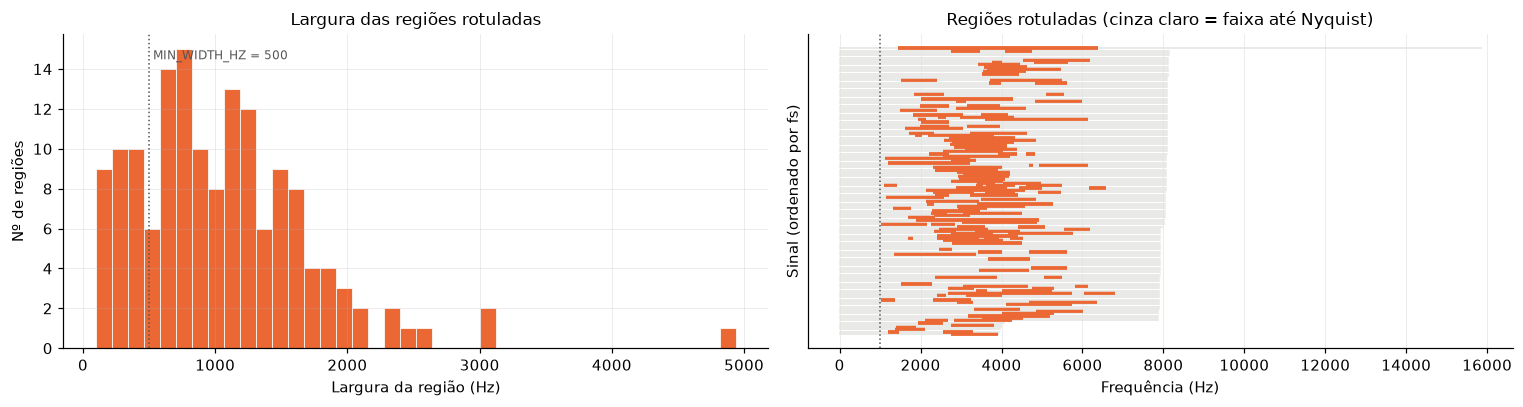

In [62]:
MIN_WIDTH_HZ = 500  # largura mínima candidata para o detector
narrow = reg["width_hz"] < MIN_WIDTH_HZ
print(reg["width_hz"].describe().round(0).to_string())
print(f"\nregiões com menos de {MIN_WIDTH_HZ} Hz: {narrow.sum()} de {len(reg)} ({narrow.mean():.0%}), "
      f"somando {reg.loc[narrow, 'width_hz'].sum() / reg['width_hz'].sum():.1%} dos Hz rotulados")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(reg["width_hz"], bins=40, color=C["carpet"], edgecolor="white", linewidth=0.5)
axes[0].axvline(MIN_WIDTH_HZ, color="#555", linestyle=":", linewidth=1)
axes[0].text(MIN_WIDTH_HZ, axes[0].get_ylim()[1] * 0.92, f" MIN_WIDTH_HZ = {MIN_WIDTH_HZ}", fontsize=8, color="#555")
axes[0].set(xlabel="Largura da região (Hz)", ylabel="Nº de regiões", title="Largura das regiões rotuladas")

order = inv.sort_values(["fs", "n_regions"]).index
for row, sid in enumerate(order):
    axes[1].plot([0, inv.loc[sid, "fs"] / 2], [row, row], color="#e3e3e0", linewidth=1)
    for lo, hi in regions[sid]:
        axes[1].plot([lo, hi], [row, row], color=C["carpet"], linewidth=2.5, solid_capstyle="butt")
axes[1].axvline(1000, color="#555", linestyle=":", linewidth=1)
axes[1].set(xlabel="Frequência (Hz)", ylabel="Sinal (ordenado por fs)",
            title="Regiões rotuladas (cinza claro = faixa até Nyquist)")
axes[1].set_yticks([])
plt.tight_layout(); plt.show()

### 2.3 Funções de apoio e resoluções em Hz

Os sinais têm fs de 7,8 a 31,7 kHz e de 4.096 a 32.768 amostras. Um parâmetro fixo em amostras (ex.: `nperseg=1024`) dá
resoluções em Hz muito diferentes entre sinais: com 1024 pontos, uma banda de 250 Hz tem ~16 bins a 16 kHz, mas só ~8 a 31,7 kHz.
Por isso todos os parâmetros espectrais são definidos em Hz e convertidos para amostras sinal a sinal:

| Uso | Resolução alvo | Equivalente a 16 kHz |
|---|---|---|
| PSD de Welch (`level_db`, `flatness`, `entropy`) | ~8 Hz | `nperseg` = 2048 (igual ao `eda_part2`) |
| STFT da curtose espectral e espectrograma do `energy_cv` | ~62,5 Hz | `nperseg` = 256 |

O `nperseg` também é limitado para garantir ao menos 4 segmentos na média de Welch (nos sinais curtos, a resolução cai para ~16 Hz).

In [63]:
WELCH_DF_HZ = 8.0       # resolução alvo da PSD de Welch
STFT_DF_HZ = 62.5       # resolução alvo da STFT (curtose espectral, espectrograma)


def nperseg_for(fs, n, target_df_hz, min_segments=4):
    # Converte uma resolução em Hz no nperseg (potência de 2) do sinal, com no mínimo `min_segments` segmentos
    nper = 2 ** int(np.round(np.log2(fs / target_df_hz)))
    return int(min(nper, 2 ** int(np.floor(np.log2(n / min_segments)))))


def amp_spectrum(x, fs):
    # Espectro de amplitude unilateral (g) com janela Hann
    w = sps.windows.hann(len(x))
    X = np.fft.rfft(x * w)
    return np.fft.rfftfreq(len(x), 1 / fs), 2 * np.abs(X) / w.sum()


def welch_db(x, fs, nperseg=None):
    nperseg = nperseg or nperseg_for(fs, len(x), WELCH_DF_HZ)
    f, p = sps.welch(x, fs, nperseg=nperseg)
    return f, 10 * np.log10(p + 1e-20)


def shade_regions(ax, sid, alpha=0.15):
    for lo, hi in regions[sid]:
        ax.axvspan(lo, hi, color=C["carpet"], alpha=alpha, linewidth=0)


def pick(index, k=1):
    index = list(index)
    return list(rng.choice(index, size=min(k, len(index)), replace=False))


def auc(score, y):
    # AUC via Mann-Whitney = P(score de um positivo > score de um negativo). 0,5 = não separa.
    score, y = np.asarray(score, float), np.asarray(y, bool)
    ok = np.isfinite(score)
    score, y = score[ok], y[ok]
    u = stats.mannwhitneyu(score[y], score[~y]).statistic
    return u / (y.sum() * (~y).sum())


def box_with_points(ax, groups, names, colors, max_points=400):
    # Boxplot sem outliers + pontos com jitter (amostrados se forem muitos)
    for k, (v, c) in enumerate(zip(groups, colors)):
        v = np.asarray(v, float); v = v[np.isfinite(v)]
        ax.boxplot(v, positions=[k], widths=0.5, showfliers=False, medianprops=dict(color="#222"),
                   boxprops=dict(color="#555"), whiskerprops=dict(color="#555"), capprops=dict(color="#555"))
        s = v if len(v) <= max_points else rng.choice(v, max_points, replace=False)
        ax.scatter(k + rng.uniform(-0.18, 0.18, len(s)), s, s=8, color=c, alpha=0.55, linewidths=0)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names)


full_length = inv.n == inv.n.max()
ex_carpet = pick(inv.index[inv.has_carpet & full_length])[0]
ex_clean = pick(inv.index[~inv.has_carpet & full_length])[0]
EXAMPLES = [(ex_carpet, "com carpet"), (ex_clean, "sem carpet")]
print("exemplo com carpet:", ex_carpet, regions[ex_carpet])
print("exemplo sem carpet:", ex_clean)

res = pd.DataFrame({
    "nperseg Welch": [nperseg_for(fs, len(x), WELCH_DF_HZ) for x, fs in signals.values()],
    "nperseg STFT": [nperseg_for(fs, len(x), STFT_DF_HZ) for x, fs in signals.values()],
}, index=list(signals))
res["df Welch (Hz)"] = inv.fs / res["nperseg Welch"]
res["df STFT (Hz)"] = inv.fs / res["nperseg STFT"]
print("\nResolução efetiva por sinal:")
print(res[["df Welch (Hz)", "df STFT (Hz)"]].describe().loc[["min", "50%", "max"]].round(1).to_string())

exemplo com carpet: ce31ebce-aa58-5112-9643-89c4559dd5ae [(1032.0, 1358.0), (2305.0, 3235.0)]
exemplo sem carpet: 94139dca-64a3-5c1e-8409-cac060300dfe

Resolução efetiva por sinal:
     df Welch (Hz)  df STFT (Hz)
min            7.7          61.3
50%            7.9          62.9
max           15.7          63.5


## 3. Domínio do tempo

### 3.1 Estatísticas globais (sinal inteiro)

RMS, média, variância, skewness, curtose e crest factor do sinal inteiro (mesmas definições do `eda_part2`).
A pergunta é se separam "tem carpet" × "não tem". Mesmo que separem, não dizem onde está o carpet.

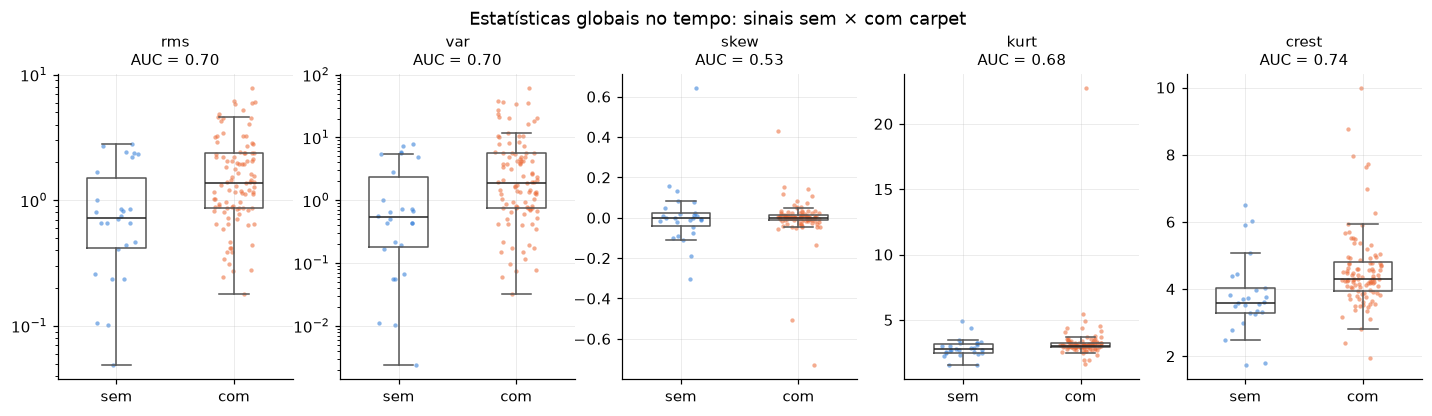

In [64]:
def time_features(x):
    rms = np.sqrt(np.mean(x ** 2))
    return {"rms": rms, "mean": np.mean(x), "var": np.var(x), "skew": stats.skew(x),
            "kurt": stats.kurtosis(x, fisher=False), "crest": np.max(np.abs(x)) / rms}


tf = pd.DataFrame({sid: time_features(x) for sid, (x, fs) in signals.items()}).T.astype(float)
tf["has_carpet"] = inv["has_carpet"].astype(bool)

cols = ["rms", "var", "skew", "kurt", "crest"]
fig, axes = plt.subplots(1, len(cols), figsize=(16, 3.6))
for ax, c in zip(axes, cols):
    box_with_points(ax, [tf.loc[~tf.has_carpet, c], tf.loc[tf.has_carpet, c]], ["sem", "com"],
                    [C["outside"], C["carpet"]])
    ax.set_title(f"{c}\nAUC = {auc(tf[c], tf.has_carpet):.2f}", fontsize=10)
    if c in ("rms", "var"):
        ax.set_yscale("log")
plt.suptitle("Estatísticas globais no tempo: sinais sem × com carpet", y=1.04)
plt.show()

### 3.2 Estatísticas por banda (filtro passa-banda + estatística no tempo)

Conecta o ramo "tempo" ao rótulo em frequência: filtrar o sinal na faixa rotulada e calcular as mesmas estatísticas.
Carpet é ruído aleatório, então o sinal filtrado deve ficar próximo de gaussiano (curtose ≈ 3, crest ≈ 3–4).
Impactos de defeito localizado elevariam curtose e crest. Como controle, uma banda de mesma largura longe de qualquer região rotulada.

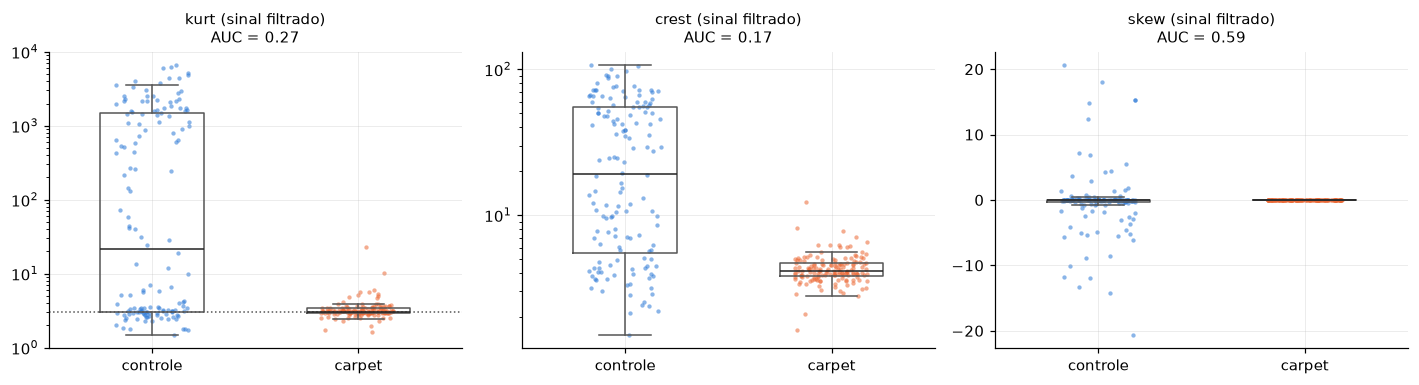

,kurt,crest,skew
band,,,
carpet,3.07,4.14,0.0
control,21.66,19.10,-0.0


In [65]:
def bandpass(x, fs, lo, hi, order=4):
    hi = min(hi, 0.49 * fs)
    sos = sps.butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return sps.sosfiltfilt(sos, x)


rows = []
for sid, rr in regions.items():
    x, fs = signals[sid]
    for lo, hi in rr:
        rows.append({"sample_id": sid, "band": "carpet", **time_features(bandpass(x, fs, lo, hi))})
        # banda de controle: mesma largura, sem sobreposição com nenhuma região rotulada
        width = hi - lo
        candidates = [(c, c + width) for c in np.arange(1000, 0.45 * fs - width, width / 2)
                      if all(c + width < a or c > b for a, b in rr)]
        if candidates:
            c_lo, c_hi = candidates[rng.integers(len(candidates))]
            rows.append({"sample_id": sid, "band": "control", **time_features(bandpass(x, fs, c_lo, c_hi))})
band_stats = pd.DataFrame(rows)

cols = ["kurt", "crest", "skew"]
is_carpet = band_stats.band == "carpet"
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, cols):
    box_with_points(ax, [band_stats.loc[~is_carpet, c], band_stats.loc[is_carpet, c]], ["controle", "carpet"],
                    [C["outside"], C["carpet"]])
    ax.set_title(f"{c} (sinal filtrado)\nAUC = {auc(band_stats[c], is_carpet):.2f}", fontsize=10)
    if c in ("kurt", "crest"):
        ax.set_yscale("log")
axes[0].axhline(3, linestyle=":", color="#555", linewidth=1)
plt.tight_layout(); plt.show()
band_stats.groupby("band")[cols].median().round(2)

## 4. Domínio da frequência

### 4.1 FFT (1ª ordem) e PSD de Welch (2ª ordem)

A FFT com resolução cheia mostra os picos individuais (o "tapete"); a PSD de Welch troca resolução por menor variância e mostra
melhor o nível da banda acima do piso. A área laranja é a região rotulada.

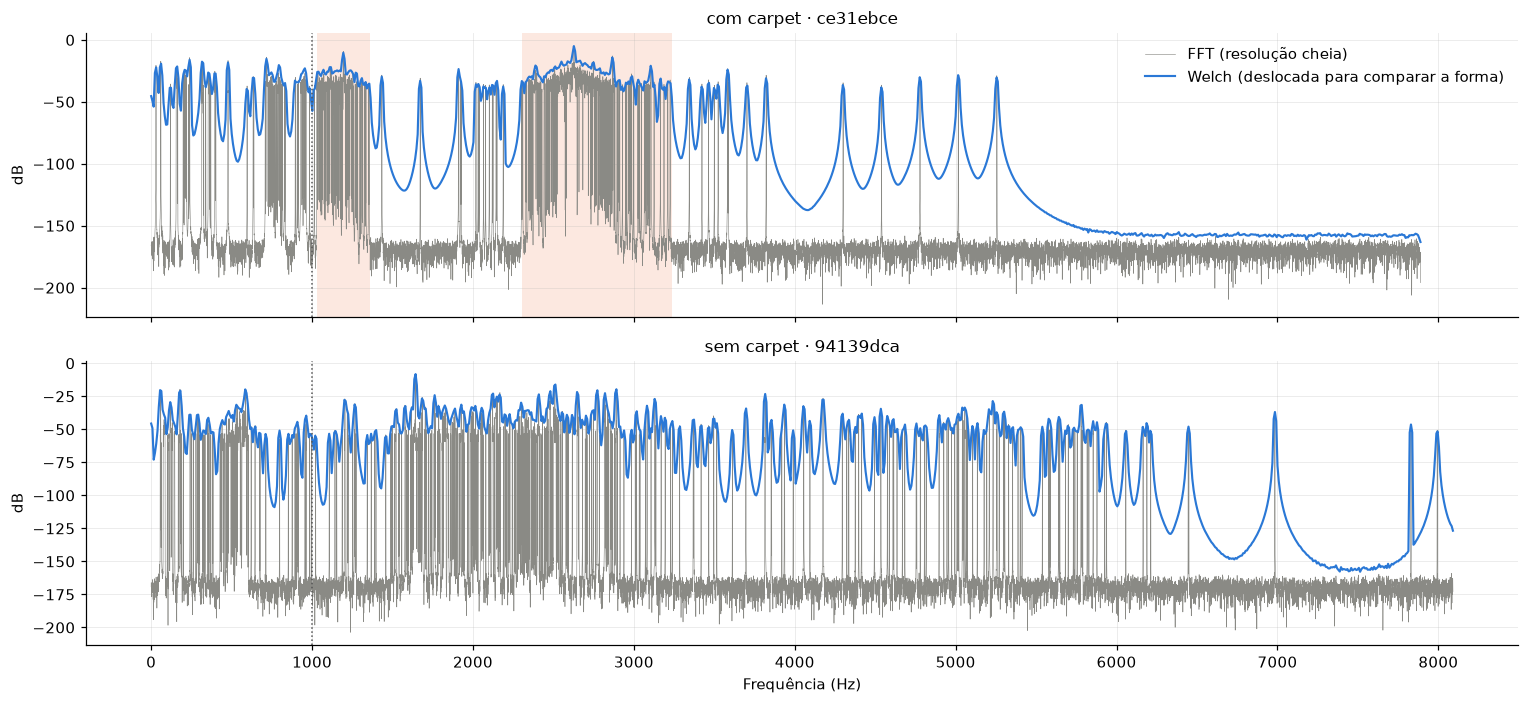

In [66]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
for ax, (sid, title) in zip(axes, EXAMPLES):
    x, fs = signals[sid]
    f, amp = amp_spectrum(x, fs)
    ax.plot(f, 20 * np.log10(amp + 1e-12), color=C["neutral"], linewidth=0.4, label="FFT (resolução cheia)")
    fw, pw = welch_db(x, fs)
    ax.plot(fw, pw - pw.max() + 20 * np.log10(amp.max()), color=C["outside"], linewidth=1.4,
            label="Welch (deslocada para comparar a forma)")
    shade_regions(ax, sid)
    ax.axvline(1000, color="#555", linestyle=":", linewidth=1)
    ax.set(title=f"{title} · {sid[:8]}", ylabel="dB")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout(); plt.show()

### 4.2 Cepstrum de potência (periodicidade no espectro)

O cepstrum é a FFT inversa do log-espectro. Harmônicos espaçados de Δf geram um pico na quefrência 1/Δf; o carpet, por ser
aleatório, não deve gerar picos cepstrais próprios. O cepstrum é global (sinal inteiro) e não vira feature por banda.

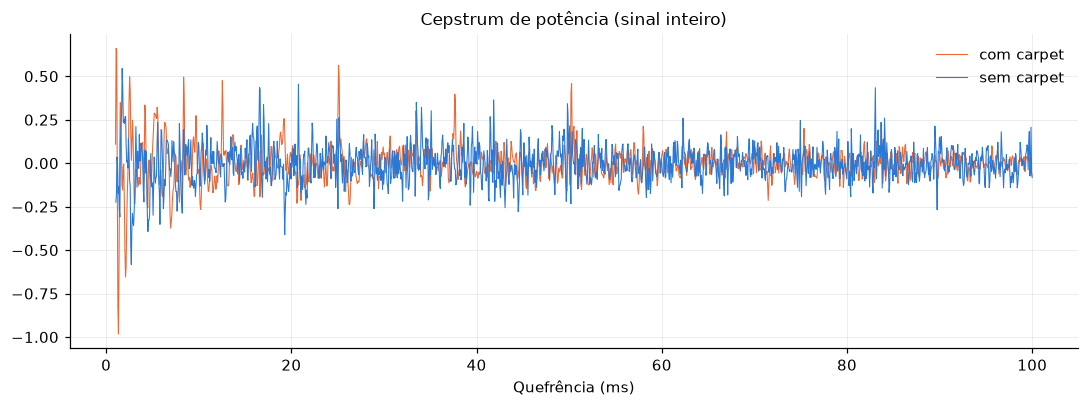

In [67]:
def power_cepstrum(x, fs):
    w = sps.windows.hann(len(x))
    log_power = np.log(np.abs(np.fft.rfft(x * w)) ** 2 + 1e-20)
    c = np.fft.irfft(log_power)
    q = np.arange(len(c)) / fs
    return q[: len(c) // 2], c[: len(c) // 2]



fig, ax = plt.subplots(figsize=(10, 3.8))
for sid, title in EXAMPLES:
    x, fs = signals[sid]
    q, c = power_cepstrum(x, fs)
    m = (q > 1e-3) & (q < 0.1)
    ax.plot(q[m] * 1000, c[m], linewidth=0.7, label=title,
            color=C["carpet"] if sid == ex_carpet else C["outside"])
ax.set(title="Cepstrum de potência (sinal inteiro)", xlabel="Quefrência (ms)")
ax.legend()
plt.tight_layout(); plt.show()

## 5. Tempo-frequência

### 5.1 Espectrograma (STFT)

O carpet é estacionário (presente o tempo todo) ou aparece em rajadas? Se for estável, a média temporal (Welch) já basta,
e a variação da energia da banda ao longo do tempo vira uma feature. As linhas laranja marcam as bordas das regiões rotuladas.

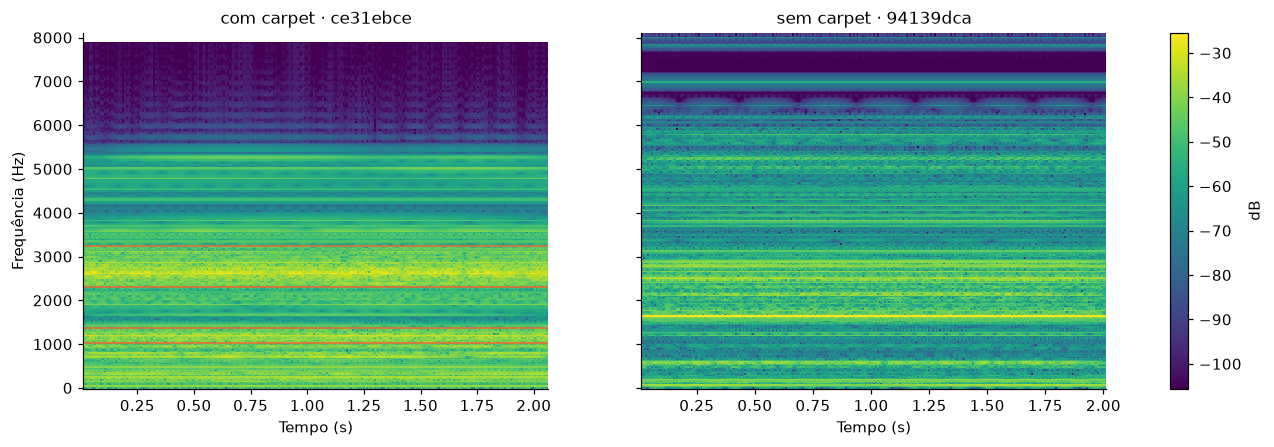

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, (sid, title) in zip(axes, EXAMPLES):
    x, fs = signals[sid]
    f, tt, S = sps.spectrogram(x, fs, nperseg=512, noverlap=384)
    S_db = 10 * np.log10(S + 1e-20)
    im = ax.pcolormesh(tt, f, S_db, shading="auto", cmap="viridis", vmin=np.percentile(S_db, 5))
    for lo, hi in regions[sid]:
        ax.axhline(lo, color=C["carpet"], linewidth=1); ax.axhline(hi, color=C["carpet"], linewidth=1)
    ax.set(title=f"{title} · {sid[:8]}", xlabel="Tempo (s)")
    ax.grid(False)
axes[0].set_ylabel("Frequência (Hz)")
fig.colorbar(im, ax=axes, label="dB")
plt.show()

### 5.2 Curtose espectral (SK)

Derivada da STFT: `SK(f) = <|X(t,f)|⁴> / <|X(t,f)|²>² − 2`. Para ruído gaussiano estacionário, SK ≈ 0. Para transientes repetitivos
(impactos de defeito localizado), a SK fica alta na banda ressonante excitada. É a base do *kurtogram* (Antoni).
Hipótese: carpet = energia alta com SK baixa; defeito localizado = energia alta com SK alta.
A PSD aparece num painel separado (mesmo eixo de frequência) para não misturar duas escalas no mesmo gráfico.

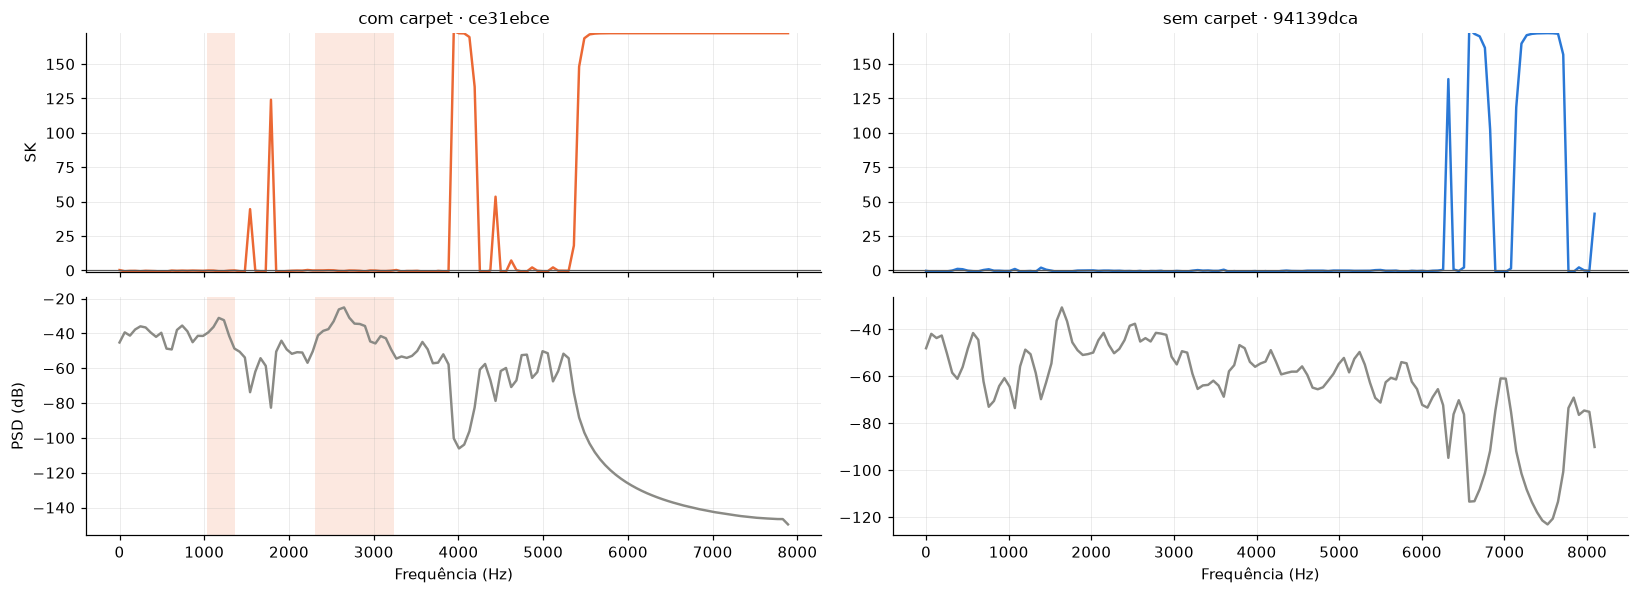

In [69]:
def spectral_kurtosis(x, fs, nperseg=None):
    nperseg = nperseg or nperseg_for(fs, len(x), STFT_DF_HZ)
    f, _, Z = sps.stft(x, fs, nperseg=nperseg, noverlap=nperseg * 3 // 4)
    p = np.abs(Z) ** 2
    return f, np.mean(p ** 2, axis=1) / (np.mean(p, axis=1) ** 2 + 1e-30) - 2


fig, axes = plt.subplots(2, 2, figsize=(15, 5.5), sharex="col")
for col, (sid, title) in enumerate(EXAMPLES):
    x, fs = signals[sid]
    f, sk = spectral_kurtosis(x, fs)
    fw, pw = welch_db(x, fs, nperseg_for(fs, len(x), STFT_DF_HZ))
    axes[0, col].plot(f, sk, color=C["carpet"] if sid == ex_carpet else C["outside"])
    axes[0, col].axhline(0, color="#555", linewidth=0.8)
    axes[0, col].set(title=f"{title} · {sid[:8]}", ylim=(-1, max(3, np.nanpercentile(sk, 99))))
    axes[1, col].plot(fw, pw, color=C["neutral"])
    for row in (0, 1):
        shade_regions(axes[row, col], sid)
    axes[1, col].set_xlabel("Frequência (Hz)")
axes[0, 0].set_ylabel("SK"); axes[1, 0].set_ylabel("PSD (dB)")
plt.tight_layout(); plt.show()

### 5.3 Wavelet contínua (escalograma Morlet)

`pywt` não está instalado e `scipy.signal.cwt` foi removido no SciPy 1.15, então a CWT Morlet é feita no domínio da frequência
(multiplicação pelo filtro gaussiano de cada escala). Mostrada só para o exemplo com carpet, num trecho de 0,5 s.
Para sinais estacionários, o escalograma traz basicamente a mesma informação do espectrograma, com resolução diferente por faixa.

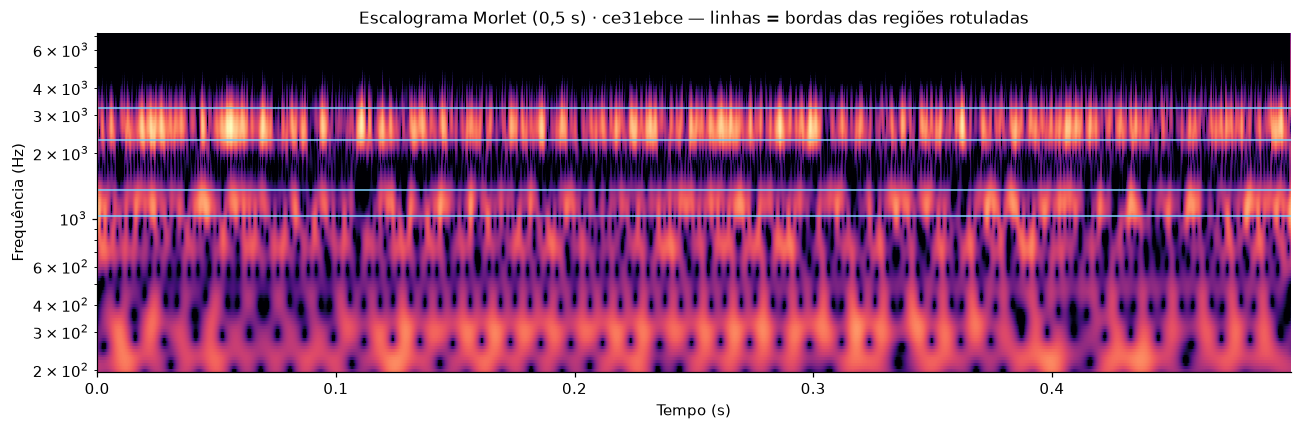

In [70]:
def cwt_morlet(x, fs, freqs, w0=6.0):
    n = len(x)
    X = np.fft.fft(x)
    omega = 2 * np.pi * np.fft.fftfreq(n, 1 / fs)
    out = np.empty((len(freqs), n), dtype=complex)
    for i, fc in enumerate(freqs):
        scale = w0 / (2 * np.pi * fc)
        psi_hat = np.pi ** -0.25 * np.exp(-0.5 * (scale * omega - w0) ** 2) * (omega > 0)
        out[i] = np.fft.ifft(X * psi_hat * np.sqrt(2 * np.pi * scale * fs))
    return out


x, fs = signals[ex_carpet]
segment = x[: int(0.5 * fs)]
freqs = np.geomspace(200, 0.45 * fs, 120)
W_db = 10 * np.log10(np.abs(cwt_morlet(segment, fs, freqs)) ** 2 + 1e-20)
fig, ax = plt.subplots(figsize=(14, 4))
ax.pcolormesh(np.arange(len(segment)) / fs, freqs, W_db, shading="auto", cmap="magma", vmin=np.percentile(W_db, 20))
for lo, hi in regions[ex_carpet]:
    ax.axhline(lo, color="#7fd3ff", linewidth=1); ax.axhline(hi, color="#7fd3ff", linewidth=1)
ax.set(yscale="log", title=f"Escalograma Morlet (0,5 s) · {ex_carpet[:8]} — linhas = bordas das regiões rotuladas",
       xlabel="Tempo (s)", ylabel="Frequência (Hz)")
ax.grid(False)
plt.show()

## 6. Demodulação: espectro de envelope

Filtra a banda, tira o envelope (Hilbert) e faz a FFT do envelope. Modulação periódica (impactos de defeito localizado,
harmônicos) gera linhas no envelope; carpet (ruído aleatório) gera um envelope sem linhas.

Feature derivada: razão *pico/mediana do espectro de envelope* entre 2 e 500 Hz (`env_peak_ratio`).
Alta = modulação periódica; baixa = carpet.

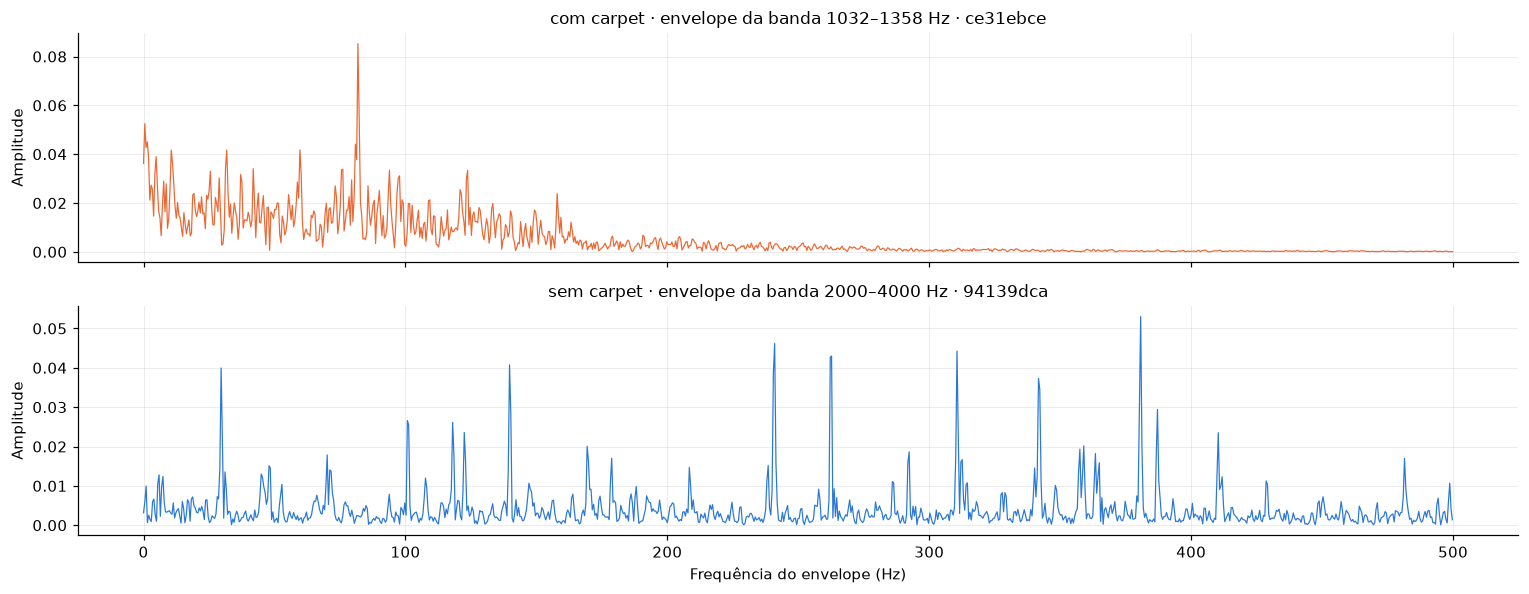

In [71]:
ENV_FMAX = 500.0


def envelope_spectrum(x, fs, lo, hi):
    env = np.abs(sps.hilbert(bandpass(x, fs, lo, hi)))
    return amp_spectrum(env - env.mean(), fs)


fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
for ax, (sid, title) in zip(axes, EXAMPLES):
    x, fs = signals[sid]
    lo, hi = regions[sid][0] if regions[sid] else (2000, 4000)
    f, e = envelope_spectrum(x, fs, lo, hi)
    m = f <= ENV_FMAX
    ax.plot(f[m], e[m], linewidth=0.8, color=C["carpet"] if sid == ex_carpet else C["outside"])
    ax.set(title=f"{title} · envelope da banda {lo:.0f}–{hi:.0f} Hz · {sid[:8]}", ylabel="Amplitude")
axes[-1].set_xlabel("Frequência do envelope (Hz)")
plt.tight_layout(); plt.show()

## 7. Ranking de features por banda: dentro × fora do carpet

Bandas de 250 Hz (passo de 125 Hz) entre 1000 Hz e 0,95·Nyquist. Banda carpet = ≥ 50% dentro de um rótulo; fora = 0%;
as ambíguas ficam fora do ranking. Separação medida por AUC (0,5 = não separa; abaixo de 0,5 = relação inversa).
`flatness` e `entropy` usam a PSD de Welch (~8 Hz), não o espectro cheio.

Cuidado: bandas vizinhas se sobrepõem, então a AUC é exploratória.

### Indicadores por banda

| Feature | O que mede | Base |
|---|---|---|
| `level_db` | Nível médio da PSD na banda − mediana do espectro (dB) | FFT/Welch (Kannan, p. 10) |
| `env_peak_ratio` | Pico / mediana do espectro de envelope (2–500 Hz) | Envelope/HFRT (Kannan, Eq. 9) |
| `sk_mean` | Curtose espectral média (STFT ~62,5 Hz) | SK (Kannan, p. 11; Antoni 2006) |
| `energy_cv` | CV da energia da banda no tempo | STFT (Kannan, p. 12) |
| `kurt` | Curtose do sinal filtrado na banda | Kannan, Eq. 7 |
| `flatness` | Média geométrica / aritmética da PSD | Planura espectral (Gray & Markel 1974) |
| `entropy` | Entropia de Shannon normalizada da PSD | Entropia espectral |

Equações e referências: [`docs/decisoes_eda_part1.md`](../docs/decisoes_eda_part1.md).

In [72]:
BAND_W, BAND_STEP = 250.0, 125.0


def band_features(sid):
    x, fs = signals[sid]
    fw, pw_db = welch_db(x, fs)
    pw = 10 ** (pw_db / 10)                              # PSD de Welch linear (para flatness/entropy)
    floor_db = np.median(pw_db[(fw >= 1000) & (fw <= 0.95 * fs / 2)])
    f_sk, sk = spectral_kurtosis(x, fs)
    nper_sg = nperseg_for(fs, len(x), STFT_DF_HZ)
    f_sg, _, S = sps.spectrogram(x, fs, nperseg=nper_sg, noverlap=nper_sg // 2)

    rows = []
    for lo in np.arange(1000, 0.95 * fs / 2 - BAND_W, BAND_STEP):
        hi = lo + BAND_W
        # fração da banda dentro de alguma região rotulada (0 = fora, ≥ 0,5 = carpet, entre os dois = ambígua)
        overlap = sum(max(0.0, min(hi, b) - max(lo, a)) for a, b in regions[sid]) / BAND_W
        energy_t = S[(f_sg >= lo) & (f_sg < hi)].sum(axis=0)
        y = bandpass(x, fs, lo, hi)                      # sinal filtrado na banda: envelope e curtose
        env = np.abs(sps.hilbert(y))
        f_env, e_env = amp_spectrum(env - env.mean(), fs)
        m_env = (f_env > 2) & (f_env <= ENV_FMAX)
        p_band = pw[(fw >= lo) & (fw < hi)]
        q_band = p_band / p_band.sum()
        rows.append({
            "sample_id": sid, "lo": lo, "overlap": min(overlap, 1.0), "in_carpet": overlap >= 0.5,
            "kurt": stats.kurtosis(y, fisher=False),
            "level_db": pw_db[(fw >= lo) & (fw < hi)].mean() - floor_db,
            "env_peak_ratio": e_env[m_env].max() / (np.median(e_env[m_env]) + 1e-20),
            "sk_mean": sk[(f_sk >= lo) & (f_sk < hi)].mean(),
            "energy_cv": energy_t.std() / (energy_t.mean() + 1e-30),
            "flatness": np.exp(np.mean(np.log(p_band + 1e-30))) / np.mean(p_band),
            "entropy": -(q_band * np.log(q_band + 1e-30)).sum() / np.log(len(q_band)),
        })
    return rows


bands = pd.DataFrame([r for sid in signals for r in band_features(sid)])   # todas as bandas (o detector classifica todas)
labeled = bands[(bands.overlap == 0) | (bands.overlap >= 0.5)].reset_index(drop=True)   # sem as ambíguas (análise)
BAND_FEATS = ["level_db", "env_peak_ratio", "kurt", "sk_mean", "energy_cv", "flatness", "entropy"]
LOG_SCALE = {"env_peak_ratio", "energy_cv", "kurt"}
print(f"{len(bands)} bandas no total | {len(bands) - len(labeled)} ambíguas (fora da análise) | "
      f"{int(labeled.in_carpet.sum())} carpet | {int((~labeled.in_carpet).sum())} fora")

6364 bandas no total | 271 ambíguas (fora da análise) | 1245 carpet | 4848 fora


,AUC,mediana carpet,mediana fora,"|AUC−0,5|"
level_db,0.960,73.523,-9.037,0.460
env_peak_ratio,0.225,28.510,125.271,0.275
sk_mean,0.228,-0.031,87.852,0.272
kurt,0.328,3.002,168.434,0.172
energy_cv,0.398,0.574,0.692,0.102
entropy,0.555,0.887,0.807,0.055
flatness,0.539,0.574,0.342,0.039


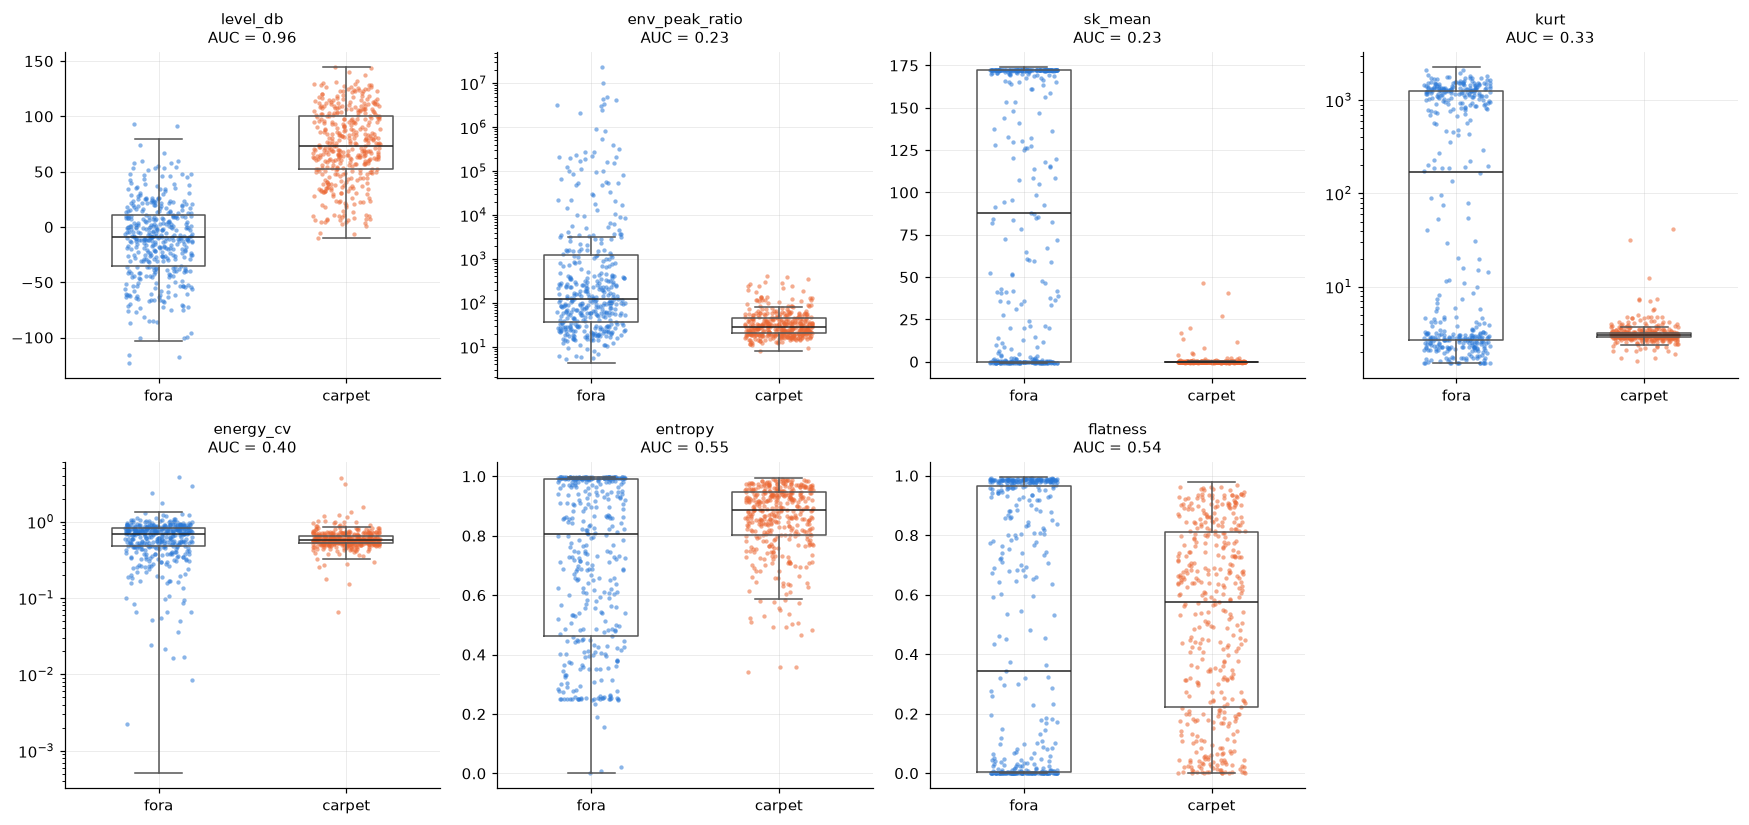

In [73]:
def rank_features(df):
    y = df["in_carpet"].values
    t = pd.DataFrame({
        "AUC": [auc(df[c], y) for c in BAND_FEATS],
        "mediana carpet": [df.loc[df.in_carpet, c].median() for c in BAND_FEATS],
        "mediana fora": [df.loc[~df.in_carpet, c].median() for c in BAND_FEATS],
    }, index=BAND_FEATS)
    t["|AUC−0,5|"] = (t["AUC"] - 0.5).abs()
    return t.sort_values("|AUC−0,5|", ascending=False)


def plot_ranked(df, ranking, outside_name):
    ncols = 4
    nrows = int(np.ceil(len(BAND_FEATS) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.8 * nrows))
    axes = axes.ravel()
    for ax in axes[len(BAND_FEATS):]:
        ax.set_visible(False)
    for ax, c in zip(axes, ranking.index):
        box_with_points(ax, [df.loc[~df.in_carpet, c], df.loc[df.in_carpet, c]], [outside_name, "carpet"],
                        [C["outside"], C["carpet"]])
        ax.set_title(f"{c}\nAUC = {ranking.loc[c, 'AUC']:.2f}", fontsize=10)
        if c in LOG_SCALE:
            ax.set_yscale("log")
    plt.tight_layout(); plt.show()


ranking = rank_features(labeled)
display(ranking.round(3))
plot_ranked(labeled, ranking, "fora")

### 7.1 Redundância entre features

Correlação de Spearman entre as features nas bandas. Pares muito correlacionados medem a mesma coisa; vale manter o mais simples
ou mais interpretável.

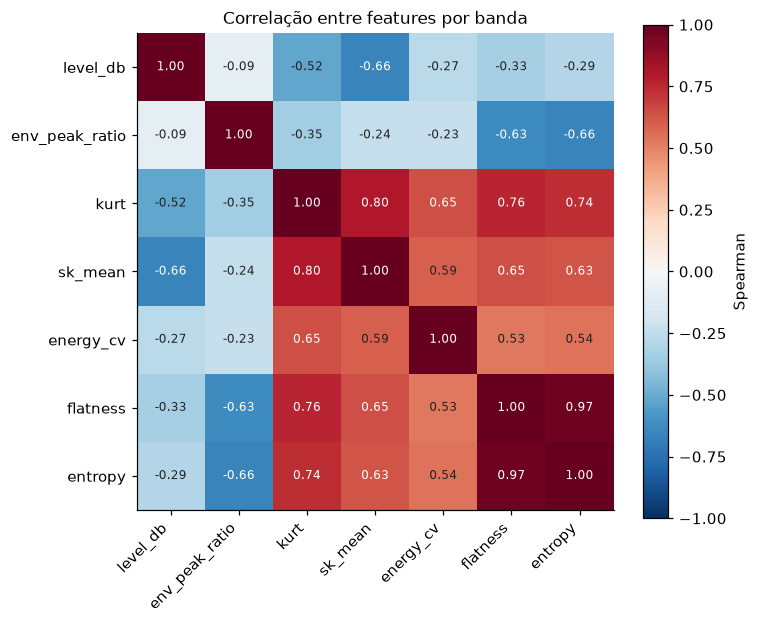

In [74]:
corr = labeled[BAND_FEATS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(BAND_FEATS))); ax.set_xticklabels(BAND_FEATS, rotation=45, ha="right")
ax.set_yticks(range(len(BAND_FEATS))); ax.set_yticklabels(BAND_FEATS)
for i in range(len(BAND_FEATS)):
    for j in range(len(BAND_FEATS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#222")
ax.grid(False); fig.colorbar(im, ax=ax, label="Spearman")
ax.set_title("Correlação entre features por banda")
plt.tight_layout(); plt.show()

### 7.2 Perfil das melhores features ao longo da frequência

Para sinais com carpet: as duas features de maior separação plotadas banda a banda, com a região rotulada sombreada.
É a visão que um detector "banda a banda" usaria.

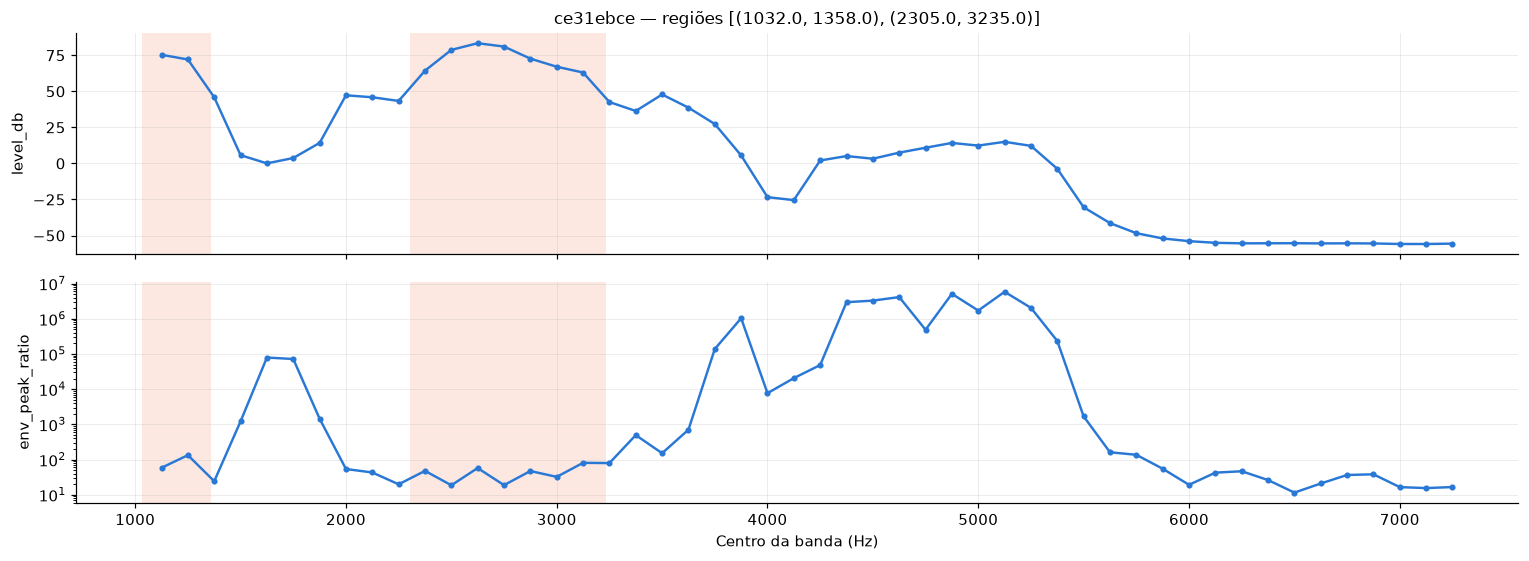

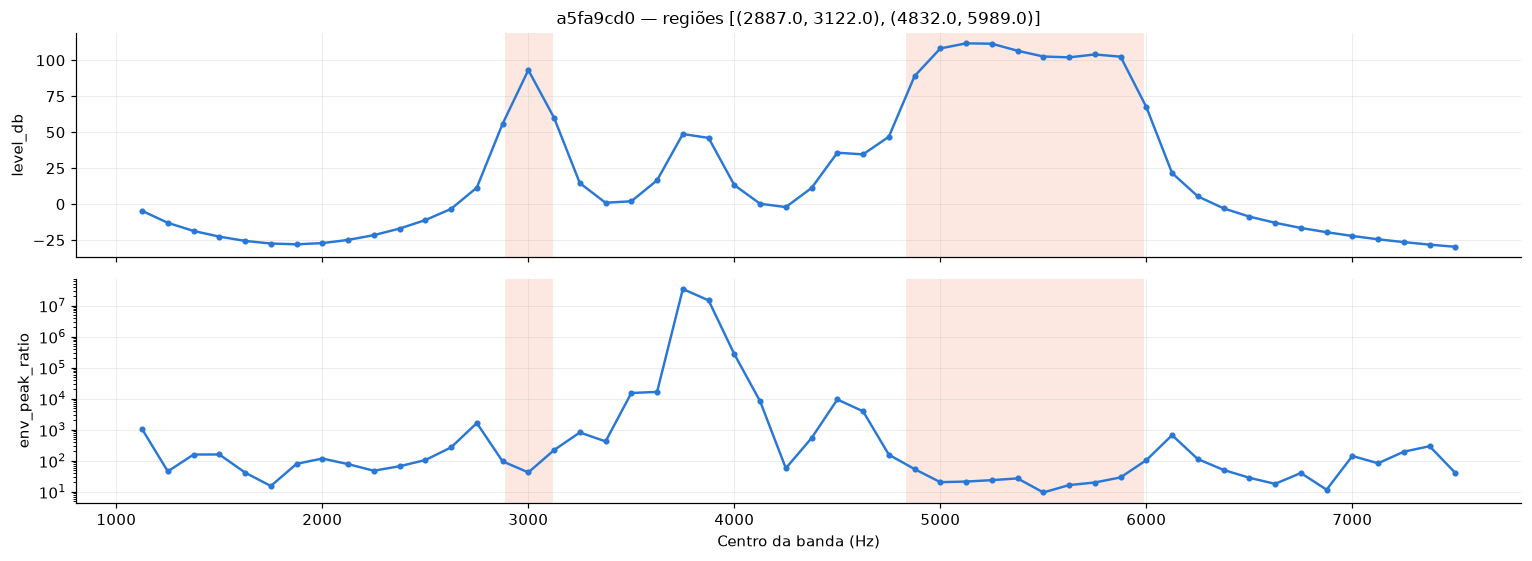

In [75]:
top2 = list(ranking.index[:2])
for sid in [ex_carpet] + pick(inv.index[inv.n_regions >= 2]):
    d = bands[bands.sample_id == sid]
    fig, axes = plt.subplots(len(top2), 1, figsize=(14, 2.6 * len(top2)), sharex=True)
    for ax, c in zip(axes, top2):
        ax.plot(d["lo"] + BAND_W / 2, d[c], marker="o", markersize=3, color=C["outside"])
        shade_regions(ax, sid)
        ax.set_ylabel(c)
        if c in LOG_SCALE:
            ax.set_yscale("log")
    axes[0].set_title(f"{sid[:8]} — regiões {regions[sid]}")
    axes[-1].set_xlabel("Centro da banda (Hz)")
    plt.tight_layout(); plt.show()

### 7.3 Recorte difícil: só bandas com energia

Fora do carpet, boa parte das bandas está no piso de ruído, então quase qualquer feature de energia separa. O caso que interessa ao
detector é outro: banda energética que é carpet × banda energética que não é (harmônicos regulares, ressonância sem tapete).
Aqui as duas classes ficam restritas a bandas com `level_db` acima de um limiar.

limiar 20.0 dB: 1157 bandas carpet | 812 fora com energia (em 109 sinais)


,AUC,mediana carpet,mediana fora,"|AUC−0,5|"
flatness,0.890,0.572,0.004,0.390
entropy,0.879,0.886,0.566,0.379
env_peak_ratio,0.122,28.870,215.433,0.378
level_db,0.874,76.495,35.709,0.374
kurt,0.641,3.009,2.795,0.141
energy_cv,0.557,0.577,0.564,0.057
sk_mean,0.520,-0.027,-0.069,0.020


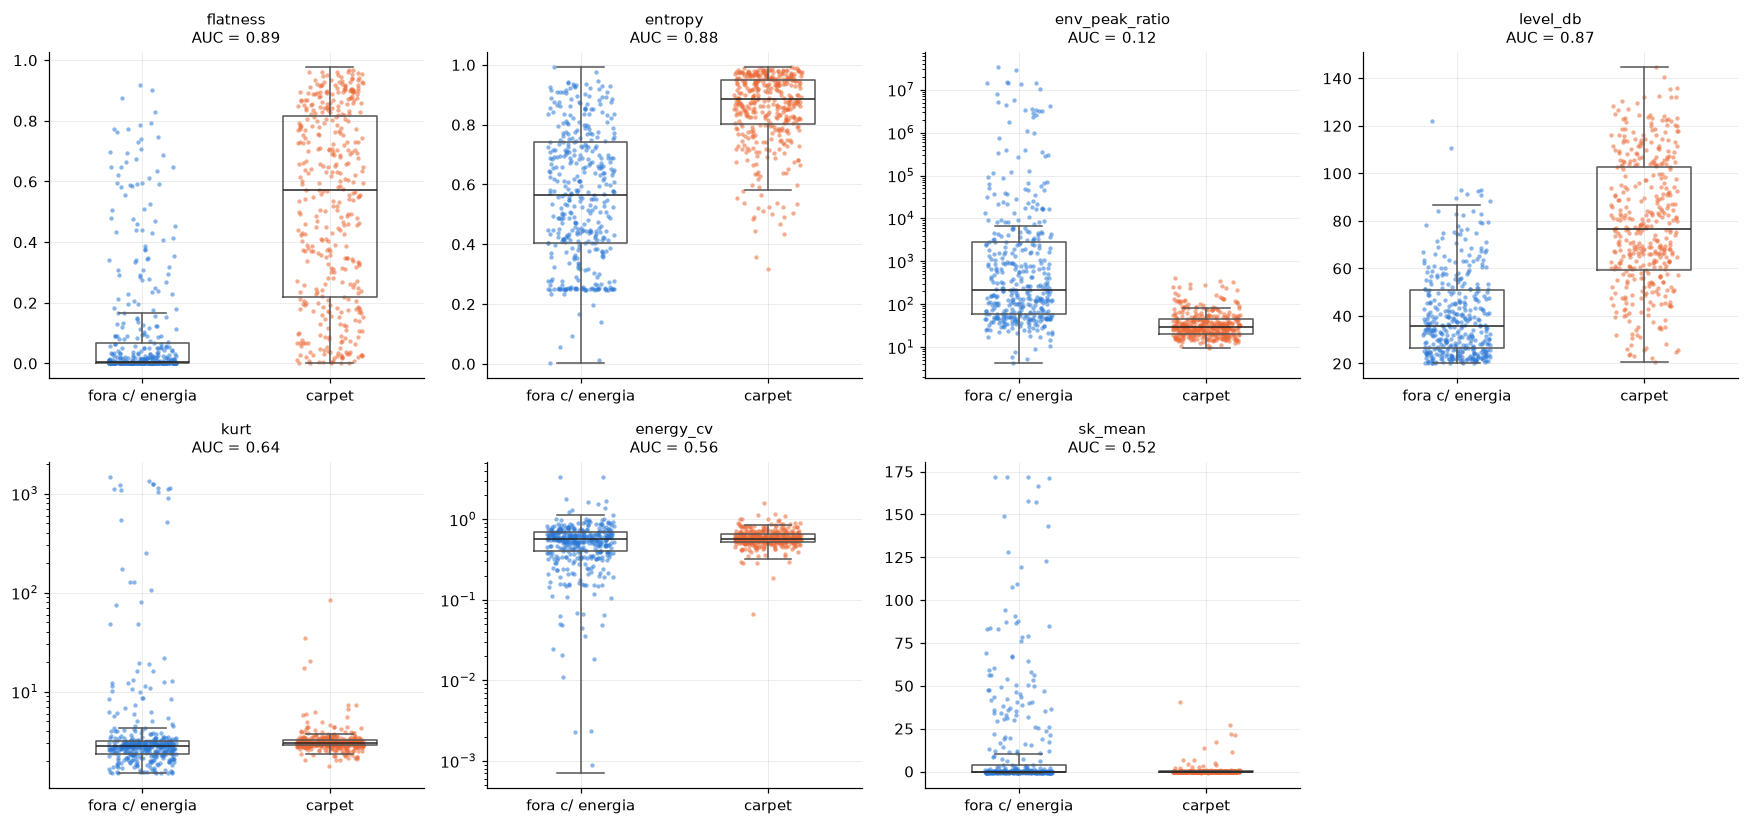

In [76]:
LEVEL_DB_MIN = 20.0
hard = labeled[labeled["level_db"] > LEVEL_DB_MIN]
print(f"limiar {LEVEL_DB_MIN} dB: {int(hard.in_carpet.sum())} bandas carpet | {int((~hard.in_carpet).sum())} fora com energia "
      f"(em {hard.loc[~hard.in_carpet, 'sample_id'].nunique()} sinais)")
ranking_hard = rank_features(hard)
display(ranking_hard.round(3))
plot_ranked(hard, ranking_hard, "fora c/ energia")

## 8. Modelos de ML: das bandas às regiões detectadas

Regressão logística (baseline), SVM, Random Forest e k-NN classificam cada banda (probabilidade > 0,5) com 6 features (sem `entropy`).

- Regiões: banda aceita cobre `centro ± 62,5 Hz`; gaps ≤ 250 Hz se juntam; regiões < 500 Hz são descartadas; início estritamente > 1000 Hz.
- Métrica: IoU em Hz por sinal (rótulos unidos). Sinal limpo sem previsão = 1; com qualquer previsão = 0.
- Validação: `StratifiedGroupKFold` (5 folds) agrupado por sinal, 3 repetições. Treino só com bandas claras; teste em todas.

In [77]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

F_MIN_HZ = 1000.0
MAX_GAP_HZ = 250.0                       # mesmo padrão do detector original
MODEL_FEATS = ["level_db", "flatness", "env_peak_ratio", "kurt", "sk_mean", "energy_cv"]
LOG_FEATS = ["env_peak_ratio", "kurt", "energy_cv"]   # caudas longas: log10 antes de padronizar


def design_matrix(df):
    X = df[MODEL_FEATS].astype(float).copy()
    X[LOG_FEATS] = np.log10(X[LOG_FEATS].clip(lower=1e-9))
    return X.values


def make_methods(seed):
    imp = lambda: SimpleImputer(strategy="median")
    return {
        "Reg. logística (baseline)": make_pipeline(imp(), StandardScaler(),
                                                   LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
        "SVM (RBF)": make_pipeline(imp(), StandardScaler(), CalibratedClassifierCV(
            SVC(C=1.0, gamma="scale", class_weight="balanced"), method="sigmoid", cv=5, ensemble=False)),
        "Random Forest": make_pipeline(imp(), RandomForestClassifier(
            n_estimators=300, max_depth=6, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=seed)),
        "k-NN (k=25)": make_pipeline(imp(), StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    }

METHOD_NAMES = list(make_methods(0))

In [78]:
def bands_to_regions(lo_values, accepted):
    # Junta bandas aceitas em regiões (mesma lógica do detector original) e aplica as restrições do desafio
    lo_acc = np.sort(np.asarray(lo_values)[np.asarray(accepted, bool)])
    merged = []
    for lo in lo_acc:
        centre = lo + BAND_W / 2
        a = F_MIN_HZ + 0.5 if lo <= F_MIN_HZ else centre - BAND_STEP / 2   # requisito b: estritamente > 1000 Hz
        b = centre + BAND_STEP / 2
        if merged and a - merged[-1][1] <= MAX_GAP_HZ:
            merged[-1][1] = b
        else:
            merged.append([a, b])
    return [(a, b) for a, b in merged if b - a >= MIN_WIDTH_HZ]   # sem sobreposição por construção


def hz_mask(intervals, nyquist):
    grid = np.arange(F_MIN_HZ, nyquist, 1.0) + 0.5               # grade de 1 Hz (precisão da anotação)
    m = np.zeros(grid.size, bool)
    for a, b in intervals:
        m |= (grid >= a) & (grid < b)
    return m


def score_signal(pred, true, nyquist):
    p, t = hz_mask(pred, nyquist), hz_mask(true, nyquist)
    inter, union = int((p & t).sum()), int((p | t).sum())
    return {"iou": 1.0 if union == 0 else inter / union, "tp_hz": inter, "pred_hz": int(p.sum()), "true_hz": int(t.sum())}


X_all = design_matrix(bands)
y_all = bands["in_carpet"].values
groups_all = bands["sample_id"].values
is_labeled = ((bands.overlap == 0) | (bands.overlap >= 0.5)).values


def cross_validate_detector(n_repeats=3, n_splits=5):
    sig_rows, band_rows = [], []
    for rep in range(n_repeats):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=rep)
        for fold, (tr, te) in enumerate(cv.split(X_all, y_all, groups_all)):
            tr = tr[is_labeled[tr]]                               # treino só com bandas claras
            for name, mdl in make_methods(rep).items():
                mdl.fit(X_all[tr], y_all[tr])
                p = mdl.predict_proba(X_all[te])[:, 1]
                lab_te = is_labeled[te]
                band_rows.append({"method": name, "rep": rep, "fold": fold,
                                  "band_auc": roc_auc_score(y_all[te][lab_te], p[lab_te])})
                te_df = bands.iloc[te].assign(p=p)
                for sid, d in te_df.groupby("sample_id"):
                    pred = bands_to_regions(d["lo"].values, d["p"].values > 0.5)
                    s = score_signal(pred, regions[sid], inv.loc[sid, "fs"] / 2)
                    sig_rows.append({"method": name, "rep": rep, "sample_id": sid,
                                     "has_carpet": bool(inv.loc[sid, "has_carpet"]), "n_pred": len(pred), **s})
    return pd.DataFrame(sig_rows), pd.DataFrame(band_rows)


SIG, BAND_AUC = cross_validate_detector()
print(f"{SIG.sample_id.nunique()} sinais avaliados × {SIG.method.nunique()} métodos × {SIG.rep.nunique()} repetições")

126 sinais avaliados × 4 métodos × 3 repetições


In [79]:
def detector_metrics(g):
    tp, pred, true = g.tp_hz.sum(), g.pred_hz.sum(), g.true_hz.sum()
    prec = tp / pred if pred else np.nan
    rec = tp / true
    clean = g[~g.has_carpet]
    return pd.Series({
        "IoU médio por sinal": g.iou.mean(),
        "IoU (sinais com carpet)": g[g.has_carpet].iou.mean(),
        "sinais sem carpet corretos": (clean.n_pred == 0).mean(),
        "precisão (Hz)": prec, "recall (Hz)": rec,
        "F1 (Hz)": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
    })

per_rep = SIG.groupby(["method", "rep"]).apply(detector_metrics)
per_rep = per_rep.join(BAND_AUC.groupby(["method", "rep"]).band_auc.mean().rename("AUC por banda"))
mean, std = per_rep.groupby("method").mean(), per_rep.groupby("method").std()
table = pd.DataFrame({c: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])] for c in mean.columns},
                     index=mean.index).loc[METHOD_NAMES]
print("Média ± desvio em 3 repetições de 5-fold agrupado por sinal (126 sinais)")
table

Média ± desvio em 3 repetições de 5-fold agrupado por sinal (126 sinais)


,IoU médio por sinal,IoU (sinais com carpet),sinais sem carpet corretos,precisão (Hz),recall (Hz),F1 (Hz),AUC por banda
method,,,,,,,
Reg. logística (baseline),0.693 ± 0.003,0.740 ± 0.007,0.513 ± 0.022,0.714 ± 0.003,0.946 ± 0.001,0.814 ± 0.002,0.986 ± 0.000
SVM (RBF),0.758 ± 0.010,0.748 ± 0.008,0.795 ± 0.022,0.810 ± 0.004,0.893 ± 0.009,0.849 ± 0.006,0.979 ± 0.000
Random Forest,0.709 ± 0.010,0.737 ± 0.007,0.603 ± 0.022,0.741 ± 0.001,0.930 ± 0.001,0.825 ± 0.001,0.985 ± 0.000
k-NN (k=25),0.779 ± 0.008,0.754 ± 0.004,0.872 ± 0.022,0.853 ± 0.004,0.869 ± 0.004,0.861 ± 0.004,0.981 ± 0.001


Como ler: IoU médio por sinal é a métrica principal. AUC por banda alta com IoU baixo = problema no limiar ou no pós-processamento.

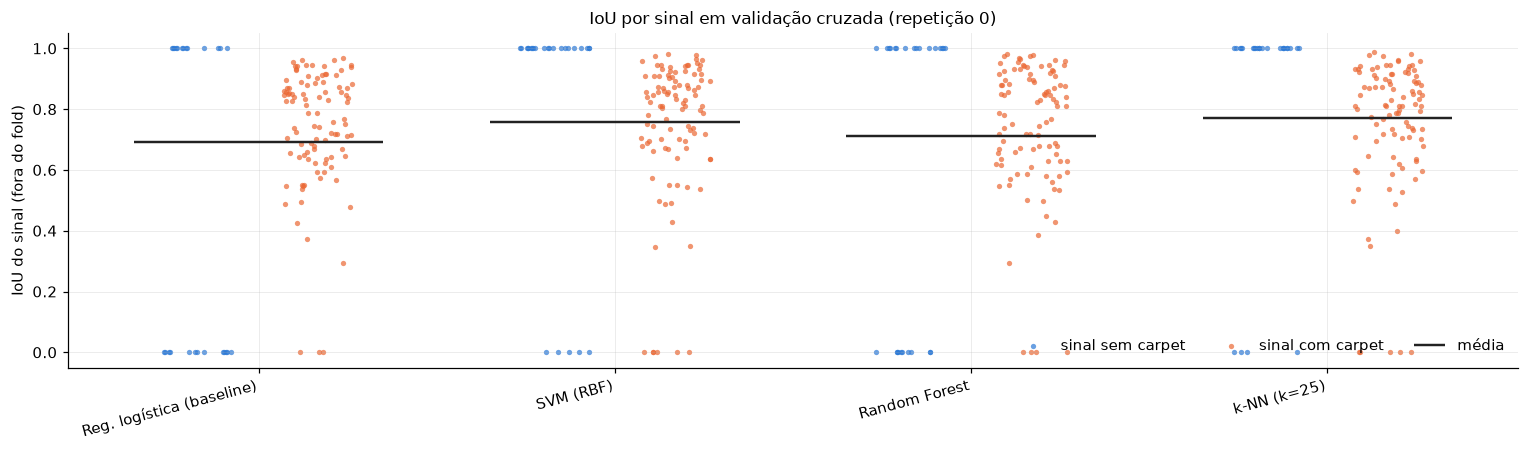

In [80]:
# IoU por sinal em cada método (repetição 0)
S0 = SIG.query("rep == 0")
fig, ax = plt.subplots(figsize=(14, 4.2))
for k, name in enumerate(METHOD_NAMES):
    g = S0[S0.method == name]
    for has, lab in [(False, "outside"), (True, "carpet")]:
        v = g[g.has_carpet == has].iou.values
        ax.scatter(k + (0.17 if has else -0.17) + rng.uniform(-0.1, 0.1, len(v)), v, s=12, color=C[lab],
                   alpha=0.7, linewidths=0, label=("sinal com carpet" if has else "sinal sem carpet") if k == 0 else None)
    ax.hlines(g.iou.mean(), k - 0.35, k + 0.35, color="#222", linewidth=1.6, label="média" if k == 0 else None)
ax.set_xticks(range(len(METHOD_NAMES))); ax.set_xticklabels(METHOD_NAMES, rotation=15, ha="right")
ax.set(ylabel="IoU do sinal (fora do fold)", ylim=(-0.05, 1.05), title="IoU por sinal em validação cruzada (repetição 0)")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

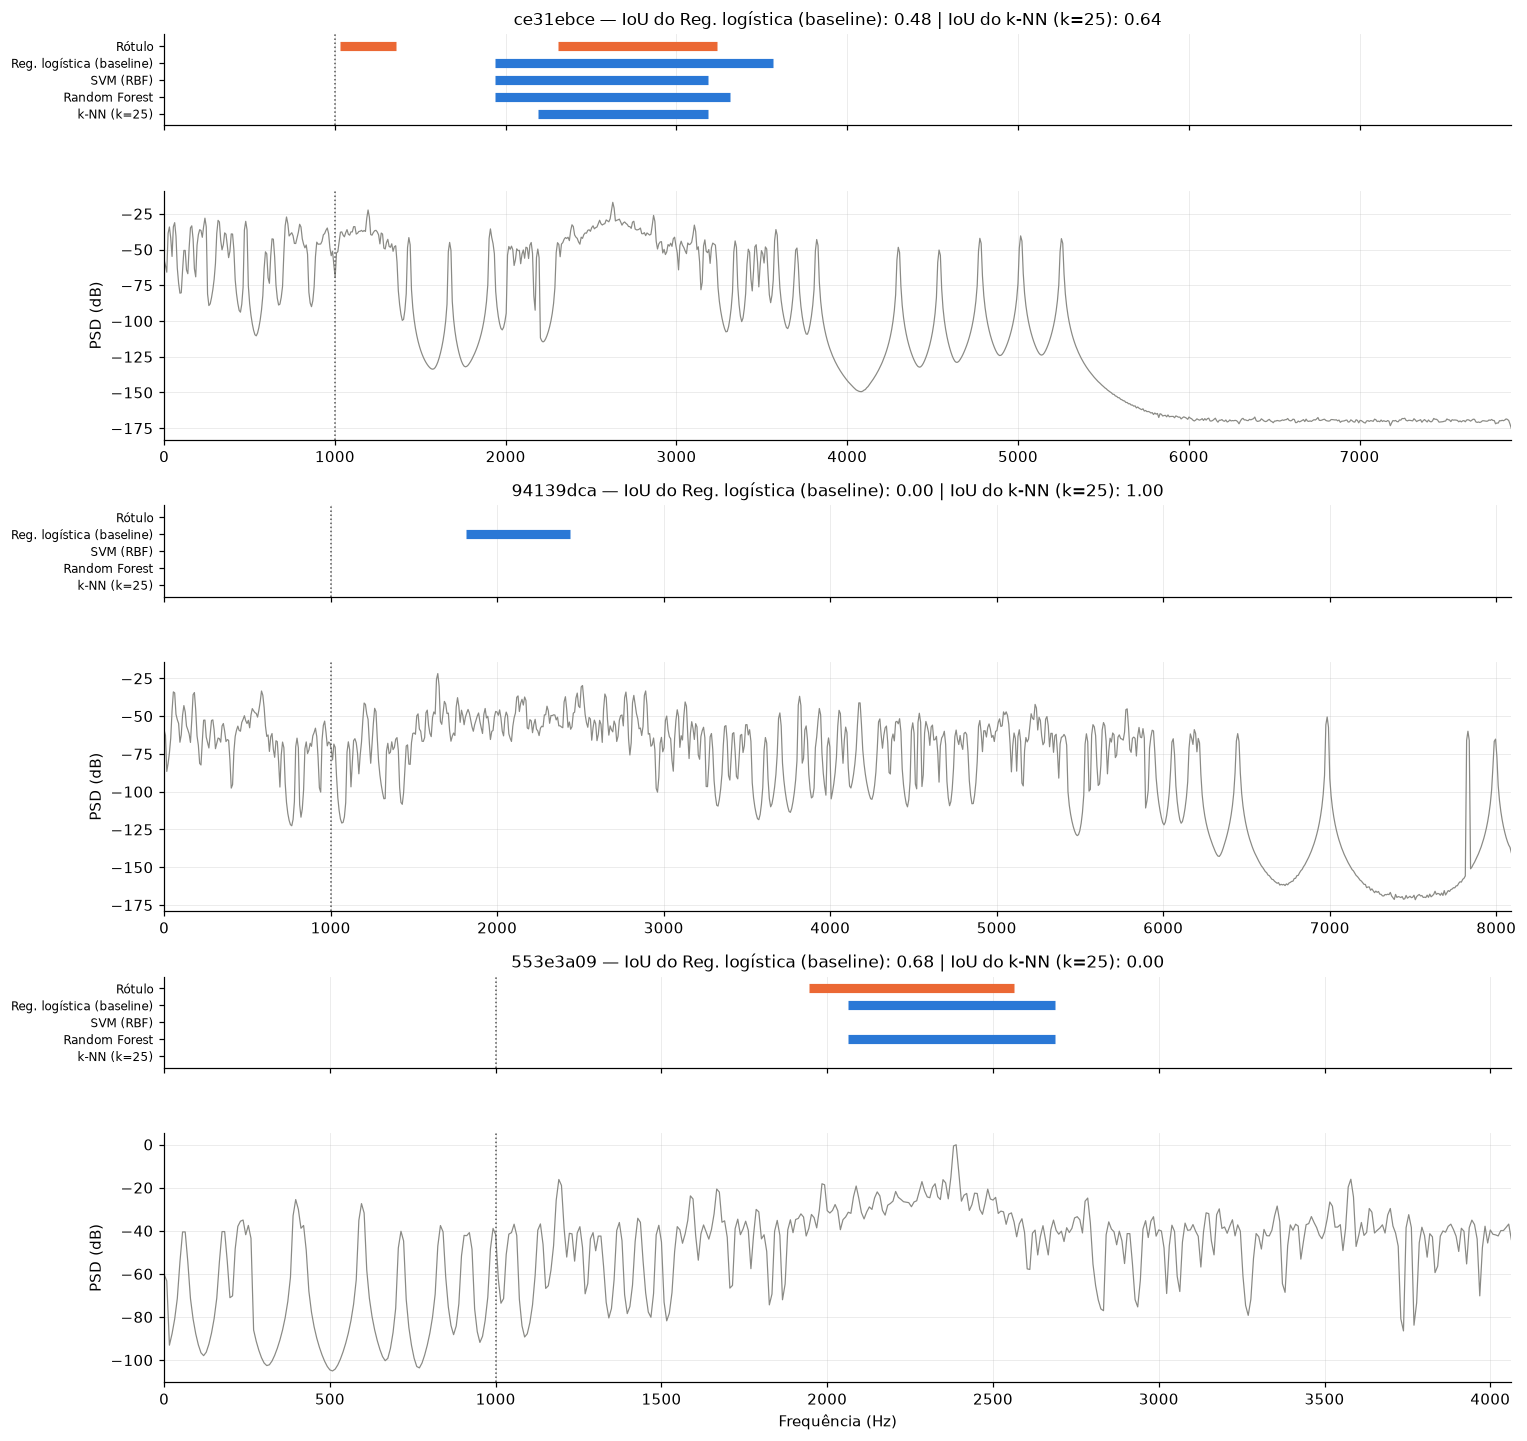

In [81]:
# Exemplos: rótulo × regiões previstas (repetição 0) pelos quatro modelos
BASELINE = "Reg. logística (baseline)"
best_model = mean.loc[METHOD_NAMES, "IoU médio por sinal"].idxmax()
show = METHOD_NAMES


def predicted_regions(name, sid):
    # Reconstrói as regiões previstas fora do fold (repetição 0) a partir do mesmo split
    return PRED0[(name, sid)]


# guarda as regiões previstas na repetição 0 (refaz só essa repetição, barato)
PRED0 = {}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
for tr, te in cv.split(X_all, y_all, groups_all):
    tr = tr[is_labeled[tr]]
    methods = make_methods(0)
    for name in show:
        mdl = methods[name]
        mdl.fit(X_all[tr], y_all[tr]); p = mdl.predict_proba(X_all[te])[:, 1]
        for sid, d in bands.iloc[te].assign(p=p).groupby("sample_id"):
            PRED0[(name, sid)] = bands_to_regions(d["lo"].values, d["p"].values > 0.5)

iou0 = S0[S0.method == best_model].set_index("sample_id").iou
examples = [ex_carpet, ex_clean, iou0[inv.loc[iou0.index, "has_carpet"]].idxmin()]
fig, axes = plt.subplots(2 * len(examples), 1, figsize=(14, 4.4 * len(examples)),
                         gridspec_kw={"height_ratios": [1.1, 3] * len(examples)})
for k, sid in enumerate(examples):
    ax_tr, ax = axes[2 * k], axes[2 * k + 1]
    x, fs = signals[sid]
    tracks = [("Rótulo", regions[sid], C["carpet"])] + [(n, predicted_regions(n, sid), C["outside"]) for n in show]
    for r, (name, rr, col) in enumerate(tracks):
        yv = len(tracks) - 1 - r
        for a, b in rr:
            ax_tr.plot([a, b], [yv, yv], color=col, linewidth=6, solid_capstyle="butt")
    ax_tr.set(xlim=(0, fs / 2), ylim=(-0.7, len(tracks) - 0.3),
              title=f"{sid[:8]} — IoU do {BASELINE}: "
                    f"{S0[(S0.method == BASELINE) & (S0.sample_id == sid)].iou.iloc[0]:.2f} | "
                    f"IoU do {best_model}: {iou0[sid]:.2f}")
    ax_tr.set_yticks(range(len(tracks))); ax_tr.set_yticklabels([t[0] for t in tracks][::-1], fontsize=8)
    ax_tr.set_xticklabels([]); ax_tr.grid(axis="y", visible=False)
    fw, pw_db = welch_db(x, fs)
    ax.plot(fw, pw_db, color=C["neutral"], linewidth=0.8)
    for a_ in (ax, ax_tr):
        a_.axvline(F_MIN_HZ, color="#555", linestyle=":", linewidth=1)
    ax.set(xlim=(0, fs / 2), ylabel="PSD (dB)")
axes[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout(); plt.show()

### 8.1 O ganho sobre a baseline é real?

Bootstrap pareado sobre os 126 sinais: IoU de cada sinal contra o da regressão logística no mesmo sinal.

In [82]:
per_signal = SIG.groupby(["method", "sample_id"]).iou.mean().unstack(0)[METHOD_NAMES]
base = per_signal[BASELINE]
boot_rng = np.random.default_rng(42)
idx = boot_rng.integers(0, len(per_signal), size=(5000, len(per_signal)))
rows = []
for name in METHOD_NAMES[1:]:
    diff = (per_signal[name] - base).values
    boots = diff[idx].mean(axis=1)
    rows.append({"método": name, "Δ IoU médio vs baseline": diff.mean(),
                 "IC 95% inferior": np.percentile(boots, 2.5), "IC 95% superior": np.percentile(boots, 97.5),
                 "sinais melhores": int((diff > 0.01).sum()), "sinais piores": int((diff < -0.01).sum())})
paired = pd.DataFrame(rows).set_index("método")
paired["ganho claro?"] = np.where(paired["IC 95% inferior"] > 0, "sim", np.where(paired["IC 95% superior"] < 0, "pior", "não"))
paired.round(3)

,Δ IoU médio vs baseline,IC 95% inferior,IC 95% superior,sinais melhores,sinais piores,ganho claro?
método,,,,,,
SVM (RBF),0.065,0.021,0.112,58,17,sim
Random Forest,0.016,-0.009,0.047,45,20,não
k-NN (k=25),0.086,0.038,0.136,61,25,sim


## 9. Conclusões

Dados: 126 sinais (100 com carpet, 150 regiões; 26 limpos), sem NaN nem saturação. fs de 7,8 a 31,7 kHz → parâmetros em Hz.
2 sinais têm rótulos sobrepostos (unidos na métrica). 21% das regiões têm < 500 Hz e nunca são detectadas.

Features: `level_db` é o gatilho (AUC 0,96). Entre bandas com energia, `flatness` alta (0,89) e `env_peak_ratio` baixo (0,12, inverso)
separam carpet de harmônicos. `entropy` repete a `flatness`; `kurt` separa só do piso; as demais pouco ajudam.

Modelos (IoU médio em CV):

| Modelo | IoU | Sinais limpos corretos | Δ vs baseline |
|---|---|---|---|
| Reg. logística (baseline) | 0,693 | 51% | — |
| Random Forest | 0,709 | 60% | não |
| SVM (RBF) | 0,758 | 80% | sim |
| k-NN (k=25) | 0,779 | 87% | sim |

Decisão: detector com k-NN (k=25) sobre as 6 features: maior IoU (0,779) e mais acertos nos sinais limpos (87%).

## 10. Features do artigo que não foram calculadas

TSA, ANC, Prony, bicoerência, EMD/VMD, DWT, Wigner-Ville, cicloestacionariedade e frequências de defeito de rolamento: faltam rotação
ou geometria, ou o método não se aplica a ruído de banda larga.